In [1]:

!pip install ucimlrepo -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Load UCI dataset
dataset = fetch_ucirepo(id=165)

X = dataset.data.features.copy()
y = dataset.data.targets.copy()

# Rename columns
X.columns = [
    "Cement",
    "Blast Furnace Slag",
    "Fly Ash",
    "Water",
    "Superplasticizer",
    "Coarse Aggregate",
    "Fine Aggregate",
    "Age"
]

y.columns = ["Strength"]

# Combine features and target
df = pd.concat([X, y], axis=1)

print("Dataset loaded successfully!")

print("\nFirst 5 records:")
display(df.head())

print("\nDataset shape:", df.shape)
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])


Dataset loaded successfully!

First 5 records:


,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30



Dataset shape: (1030, 9)
Total rows: 1030
Total columns: 9


In [3]:

print("DATA INFORMATION")
df.info()

print("\nSUMMARY STATISTICS")
display(df.describe())

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nDUPLICATE RECORDS")
print("Duplicate rows:", df.duplicated().sum())

# Check invalid values
print("\nInvalid values:")
print((df < 0).sum())

# Remove rows containing missing values
df = df.dropna().reset_index(drop=True)

# Keep duplicate observations because repeated concrete
# mixtures may be legitimate experimental measurements.

print("\nFinal dataset shape:", df.shape)


DATA INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Cement              1030 non-null   float64
 1   Blast Furnace Slag  1030 non-null   float64
 2   Fly Ash             1030 non-null   float64
 3   Water               1030 non-null   float64
 4   Superplasticizer    1030 non-null   float64
 5   Coarse Aggregate    1030 non-null   float64
 6   Fine Aggregate      1030 non-null   float64
 7   Age                 1030 non-null   int64  
 8   Strength            1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB

SUMMARY STATISTICS


,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000



MISSING VALUES
Cement                0
Blast Furnace Slag    0
Fly Ash               0
Water                 0
Superplasticizer      0
Coarse Aggregate      0
Fine Aggregate        0
Age                   0
Strength              0
dtype: int64

DUPLICATE RECORDS
Duplicate rows: 25

Invalid values:
Cement                0
Blast Furnace Slag    0
Fly Ash               0
Water                 0
Superplasticizer      0
Coarse Aggregate      0
Fine Aggregate        0
Age                   0
Strength              0
dtype: int64

Final dataset shape: (1030, 9)


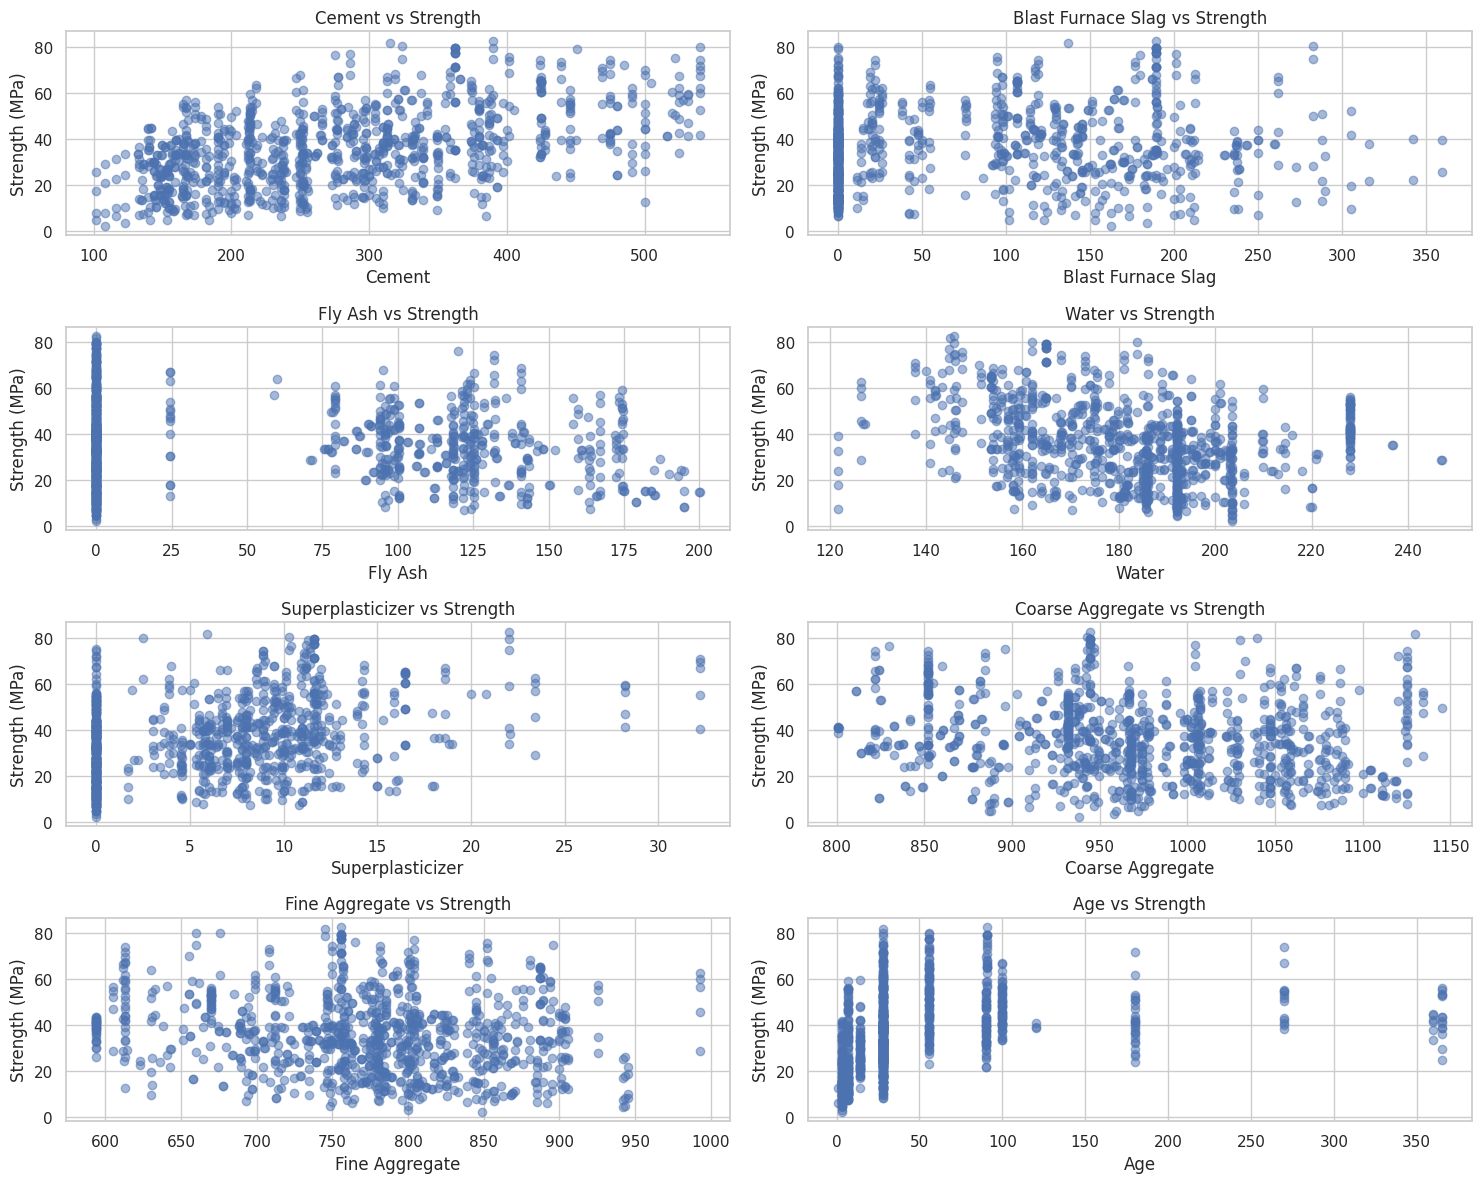

In [4]:

features = X.columns

plt.figure(figsize=(15, 12))

for i, feature in enumerate(features):
    plt.subplot(4, 2, i + 1)

    plt.scatter(
        df[feature],
        df["Strength"],
        alpha=0.5
    )

    plt.title(feature + " vs Strength")
    plt.xlabel(feature)
    plt.ylabel("Strength (MPa)")

plt.tight_layout()
plt.show()


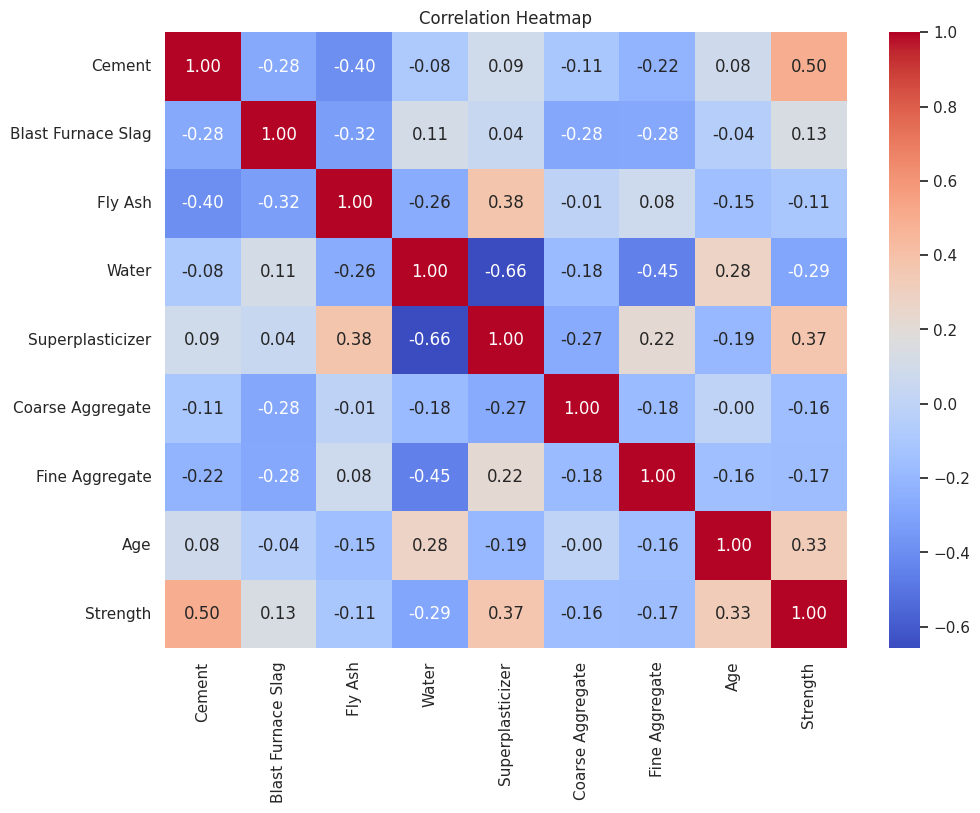


Correlation with Strength:
Strength              1.000000
Cement                0.497832
Superplasticizer      0.366079
Age                   0.328873
Blast Furnace Slag    0.134829
Fly Ash              -0.105755
Coarse Aggregate     -0.164935
Fine Aggregate       -0.167241
Water                -0.289633
Name: Strength, dtype: float64


In [5]:

correlation = df.corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

print("\nCorrelation with Strength:")
print(
    correlation["Strength"]
    .sort_values(ascending=False)
)


In [6]:

# Select 6 observations
sample = df[
    ["Cement", "Age", "Strength"]
].sample(n=6, random_state=42).reset_index(drop=True)

print("Selected sample:")
display(sample)

# Extract values
x1 = sample["Cement"].values
x2 = sample["Age"].values
y_sample = sample["Strength"].values

# Design matrix
X_manual = np.column_stack([
    np.ones(len(sample)),
    x1,
    x2
])

Y_manual = y_sample.reshape(-1, 1)

print("\nDesign Matrix X:")
print(X_manual)

print("\nTarget Vector Y:")
print(Y_manual)

# Transpose
XT = X_manual.T

# Normal equation components
XTX = XT @ X_manual
XTY = XT @ Y_manual

print("\nX transpose:")
print(XT)

print("\nXTX:")
print(XTX)

print("\nXTY:")
print(XTY)

# Solve normal equations
b = np.linalg.solve(XTX, XTY)

b0, b1, b2 = b.flatten()

print("\nRegression coefficients:")
print("Intercept b0:", b0)
print("Cement coefficient b1:", b1)
print("Age coefficient b2:", b2)

print("\nManual regression equation:")
print(
    f"Strength = {b0:.4f} + "
    f"{b1:.4f}*Cement + {b2:.4f}*Age"
)

# Prediction for first observation
actual = y_sample[0]

predicted = b0 + b1*x1[0] + b2*x2[0]

residual = actual - predicted

print("\nFirst observation prediction:")
print("Actual:", actual)
print("Predicted:", predicted)
print("Residual:", residual)


Selected sample:


,Cement,Age,Strength
0,266.0,365,52.91
1,362.6,7,55.90
2,389.9,28,74.50
3,362.6,3,35.30
4,145.0,28,10.54
5,276.4,28,44.28



Design Matrix X:
[[  1.  266.  365. ]
 [  1.  362.6   7. ]
 [  1.  389.9  28. ]
 [  1.  362.6   3. ]
 [  1.  145.   28. ]
 [  1.  276.4  28. ]]

Target Vector Y:
[[52.91]
 [55.9 ]
 [74.5 ]
 [35.3 ]
 [10.54]
 [44.28]]

X transpose:
[[  1.    1.    1.    1.    1.    1. ]
 [266.  362.6 389.9 362.6 145.  276.4]
 [365.    7.   28.    3.   28.   28. ]]

XTX:
[[6.0000000e+00 1.8025000e+03 4.5900000e+02]
 [1.8025000e+03 5.8315749e+05 1.2343240e+05]
 [4.5900000e+02 1.2343240e+05 1.3563500e+05]]

XTY:
[[  273.43 ]
 [89958.022]
 [23430.31 ]]

Regression coefficients:
Intercept b0: -20.68015916392363
Cement coefficient b1: 0.2065999501212229
Age coefficient b2: 0.05471578407415575

Manual regression equation:
Strength = -20.6802 + 0.2066*Cement + 0.0547*Age

First observation prediction:
Actual: 52.91
Predicted: 54.246688755388504
Residual: -1.3366887553885078


In [7]:

verify_model = LinearRegression()

verify_model.fit(
    sample[["Cement", "Age"]],
    sample["Strength"]
)

print("Manual intercept:", b0)
print("Library intercept:", verify_model.intercept_)

print("\nManual coefficients:")
print(b1, b2)

print("\nLibrary coefficients:")
print(verify_model.coef_)

print("\nDifference between manual and library:")
print(
    np.allclose(
        [b0, b1, b2],
        [verify_model.intercept_,
         *verify_model.coef_],
        atol=1e-7
    )
)


Manual intercept: -20.68015916392363
Library intercept: -20.680159163923427

Manual coefficients:
0.2065999501212229 0.05471578407415575

Library coefficients:
[0.20659995 0.05471578]

Difference between manual and library:
True


In [8]:

X = df.drop("Strength", axis=1)
y = df["Strength"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training data: (824, 8)
Testing data: (206, 8)
Training records: 824
Testing records: 206


In [9]:

# Select strongest feature
correlations = X_train.corrwith(y_train).abs()

best_feature = correlations.idxmax()

print("Selected feature:", best_feature)

# Train model
simple_model = LinearRegression()

simple_model.fit(
    X_train[[best_feature]],
    y_train
)

# Test predictions
simple_predictions = simple_model.predict(
    X_test[[best_feature]]
)

print("\nSimple Linear Regression")
print("Intercept:", simple_model.intercept_)
print("Coefficient:", simple_model.coef_[0])

print(
    "Test R2:",
    r2_score(y_test, simple_predictions)
)


Selected feature: Cement

Simple Linear Regression
Intercept: 13.785171881915776
Coefficient: 0.0778960679110409
Test R2: 0.25183513628298093


In [10]:

multiple_model = LinearRegression()

multiple_model.fit(X_train, y_train)

multiple_predictions = multiple_model.predict(X_test)

print("Multiple Linear Regression")

print("\nIntercept:")
print(multiple_model.intercept_)

print("\nCoefficients:")

for feature, coefficient in zip(
    X.columns,
    multiple_model.coef_
):
    print(feature, ":", coefficient)


Multiple Linear Regression

Intercept:
-28.82355499969256

Coefficients:
Cement : 0.11899393308432314
Blast Furnace Slag : 0.10853559922579054
Fly Ash : 0.08215181186302914
Water : -0.13527626344797752
Superplasticizer : 0.31056993883013073
Coarse Aggregate : 0.017867152805875412
Fine Aggregate : 0.024099778717587415
Age : 0.11643863566902143


In [11]:

equation = f"Strength = {multiple_model.intercept_:.4f}"

for feature, coefficient in zip(
    X.columns,
    multiple_model.coef_
):
    sign = "+" if coefficient >= 0 else "-"

    equation += (
        f" {sign} {abs(coefficient):.4f}"
        f"({feature})"
    )

print("MULTIPLE LINEAR REGRESSION EQUATION")
print(equation)


MULTIPLE LINEAR REGRESSION EQUATION
Strength = -28.8236 + 0.1190(Cement) + 0.1085(Blast Furnace Slag) + 0.0822(Fly Ash) - 0.1353(Water) + 0.3106(Superplasticizer) + 0.0179(Coarse Aggregate) + 0.0241(Fine Aggregate) + 0.1164(Age)


In [12]:

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

scaled_model = LinearRegression()

scaled_model.fit(
    X_train_scaled,
    y_train
)

print("STANDARDISED COEFFICIENTS")

for feature, coefficient in zip(
    X.columns,
    scaled_model.coef_
):
    print(feature, ":", round(coefficient, 4))


STANDARDISED COEFFICIENTS
Cement : 12.7884
Blast Furnace Slag : 9.4345
Fly Ash : 5.2546
Water : -2.8826
Superplasticizer : 1.8521
Coarse Aggregate : 1.4052
Fine Aggregate : 1.9505
Age : 7.0374


In [13]:

comparison = pd.DataFrame({
    "Actual Strength": y_test.values,
    "Predicted Strength": multiple_predictions
})

print("Prediction comparison:")
display(comparison.head(15))


Prediction comparison:


,Actual Strength,Predicted Strength
0,52.91,59.658042
1,55.90,52.041211
2,74.50,63.535133
3,35.30,51.575457
4,10.54,17.220017
5,44.28,39.865613
6,23.69,26.698247
7,45.37,44.736489
8,37.40,29.366198
9,48.85,38.186125


In [14]:

def evaluate_model(actual, predicted, p):

    n = len(actual)

    mae = mean_absolute_error(actual, predicted)

    mse = mean_squared_error(actual, predicted)

    rmse = np.sqrt(mse)

    r2 = r2_score(actual, predicted)

    adjusted_r2 = (
        1 - ((1-r2)*(n-1)/(n-p-1))
    )

    return [mae, mse, rmse, r2, adjusted_r2]


# Simple regression metrics
simple_metrics = evaluate_model(
    y_test,
    simple_predictions,
    1
)

# Multiple regression metrics
multiple_metrics = evaluate_model(
    y_test,
    multiple_predictions,
    X_train.shape[1]
)

results = pd.DataFrame(
    [simple_metrics, multiple_metrics],
    columns=[
        "MAE",
        "MSE",
        "RMSE",
        "R2",
        "Adjusted R2"
    ],
    index=[
        "Simple Linear Regression",
        "Multiple Linear Regression"
    ]
)

print("MODEL COMPARISON")
display(results.round(4))


MODEL COMPARISON


,MAE,MSE,RMSE,R2,Adjusted R2
Simple Linear Regression,11.5556,192.7848,13.8847,0.2518,0.2482
Multiple Linear Regression,7.7456,95.9709,9.7965,0.6276,0.6124


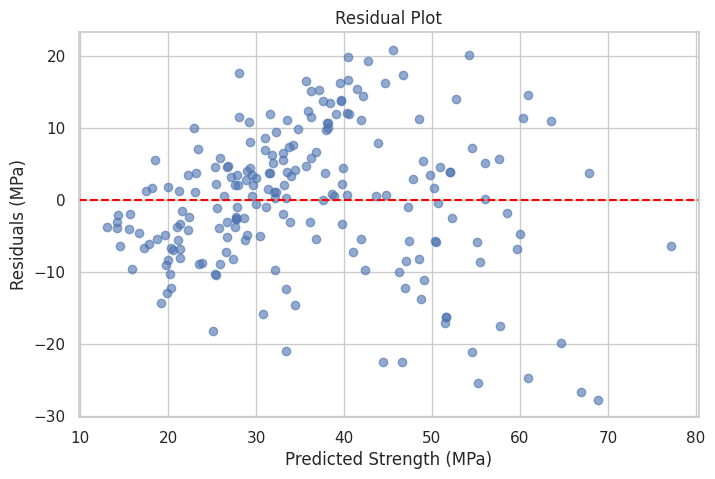

In [15]:

residuals = y_test.values - multiple_predictions

plt.figure(figsize=(8, 5))

plt.scatter(
    multiple_predictions,
    residuals,
    alpha=0.6
)

plt.axhline(0, color="red", linestyle="--")

plt.title("Residual Plot")
plt.xlabel("Predicted Strength (MPa)")
plt.ylabel("Residuals (MPa)")

plt.show()


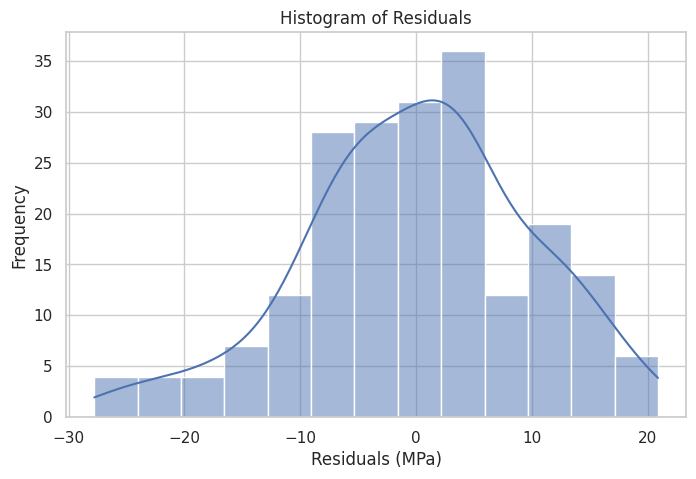

In [16]:

plt.figure(figsize=(8, 5))

sns.histplot(residuals, kde=True)

plt.title("Histogram of Residuals")
plt.xlabel("Residuals (MPa)")
plt.ylabel("Frequency")

plt.show()


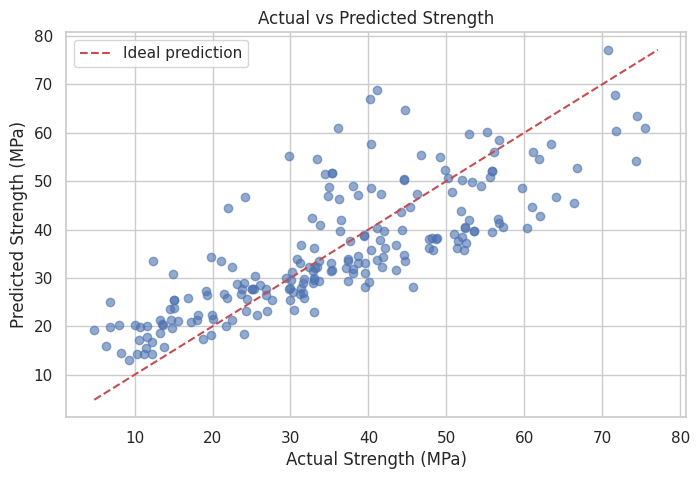

In [17]:

plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    multiple_predictions,
    alpha=0.6
)

minimum = min(y_test.min(), multiple_predictions.min())
maximum = max(y_test.max(), multiple_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "r--",
    label="Ideal prediction"
)

plt.title("Actual vs Predicted Strength")
plt.xlabel("Actual Strength (MPa)")
plt.ylabel("Predicted Strength (MPa)")
plt.legend()

plt.show()


In [18]:

vif_data = pd.DataFrame()

vif_data["Feature"] = X_train.columns

vif_data["VIF"] = [
    variance_inflation_factor(
        X_train.values, i
    )
    for i in range(X_train.shape[1])
]

print("VARIANCE INFLATION FACTOR")
display(vif_data.sort_values("VIF", ascending=False))


VARIANCE INFLATION FACTOR


,Feature,VIF
0,Cement,7.489509
1,Blast Furnace Slag,7.129776
6,Fine Aggregate,6.773558
3,Water,6.512016
2,Fly Ash,6.027833
5,Coarse Aggregate,4.923264
4,Superplasticizer,2.849369
7,Age,1.111071



LINEAR REGRESSION ASSUMPTIONS

1. Linearity:
   The relationship between input features and
   target should be approximately linear.

2. Independence:
   Residuals should be independent.

3. Homoscedasticity:
   Residuals should have constant variance.

4. Normality:
   Residuals should be approximately normally distributed.

5. Multicollinearity:
   There should not be severe correlation among
   input features.



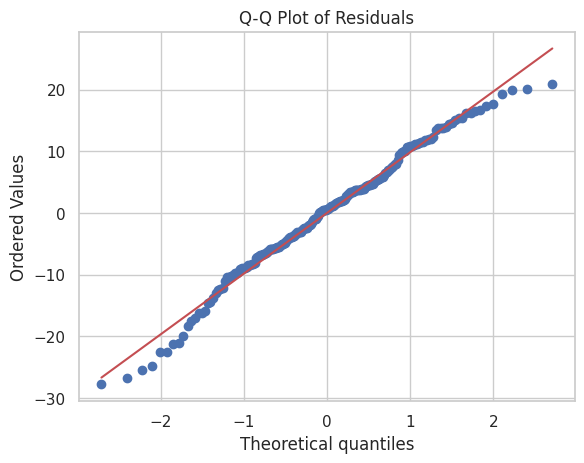

In [19]:

print("""
LINEAR REGRESSION ASSUMPTIONS

1. Linearity:
   The relationship between input features and
   target should be approximately linear.

2. Independence:
   Residuals should be independent.

3. Homoscedasticity:
   Residuals should have constant variance.

4. Normality:
   Residuals should be approximately normally distributed.

5. Multicollinearity:
   There should not be severe correlation among
   input features.
""")

# Q-Q plot for residual normality
import scipy.stats as stats

stats.probplot(
    residuals,
    dist="norm",
    plot=plt
)

plt.title("Q-Q Plot of Residuals")
plt.show()


In [22]:

print("======================================")
print(" CONCRETE STRENGTH PREDICTION SYSTEM")
print("======================================")

print("\nEnter Concrete Mixture Details:\n")

user_data = {}

for feature in X.columns:

    value = float(
        input(f"Enter {feature}: ")
    )

    user_data[feature] = value


# Convert input into DataFrame
new_data = pd.DataFrame(
    [user_data],
    columns=X.columns
)

# Check input range
print("\nChecking input ranges...")

outside_range = False

for feature in X.columns:

    minimum = X_train[feature].min()
    maximum = X_train[feature].max()

    value = new_data[feature].iloc[0]

    if value < minimum or value > maximum:

        outside_range = True

        print(
            f"WARNING: {feature} is outside "
            f"the training range "
            f"({minimum:.2f} - {maximum:.2f})"
        )

# Predict using trained Linear Regression model
prediction = multiple_model.predict(new_data)[0]

print("\n======================================")
print("          PREDICTION RESULT")
print("======================================")

print("Predicted Concrete Strength:")
print(f"{prediction:.2f} MPa")

if outside_range:
    print("\nWarning: This prediction involves extrapolation.")
    print("Treat it with additional caution.")

print("======================================")


 CONCRETE STRENGTH PREDICTION SYSTEM

Enter Concrete Mixture Details:

Enter Cement: 350
Enter Blast Furnace Slag: 0
Enter Fly Ash: 0
Enter Water: 180
Enter Superplasticizer: 5
Enter Coarse Aggregate: 1000
Enter Fine Aggregate: 800
Enter Age: 28

Checking input ranges...

          PREDICTION RESULT
Predicted Concrete Strength:
30.43 MPa


In [23]:

print("========== PROJECT CONCLUSION ==========")

print("Dataset: Concrete Compressive Strength")
print("Total records:", len(df))
print("Input features:", len(X.columns))

print("\nSimple Linear Regression R2:",
      round(simple_metrics[3], 4))

print("Multiple Linear Regression R2:",
      round(multiple_metrics[3], 4))

print("\nMultiple Regression MAE:",
      round(multiple_metrics[0], 4))

print("Multiple Regression RMSE:",
      round(multiple_metrics[2], 4))

print("""
CONCLUSION:

In this project, Linear Regression was used
to predict concrete compressive strength.

Simple Linear Regression and Multiple Linear
Regression were compared.

The model was evaluated using MAE, MSE,
RMSE, R2 and Adjusted R2.

Residual analysis and VIF were used to
investigate model assumptions and
multicollinearity.

Finally, a user-input prediction system
was developed to predict concrete strength
using multiple input features.

The model is intended for educational
purposes and not actual structural design.
""")



========== PROJECT CONCLUSION ==========
Dataset: Concrete Compressive Strength
Total records: 1030
Input features: 8

Simple Linear Regression R2: 0.2518
Multiple Linear Regression R2: 0.6276

Multiple Regression MAE: 7.7456
Multiple Regression RMSE: 9.7965

CONCLUSION:

In this project, Linear Regression was used
to predict concrete compressive strength.

Simple Linear Regression and Multiple Linear
Regression were compared.

The model was evaluated using MAE, MSE,
RMSE, R2 and Adjusted R2.

Residual analysis and VIF were used to
investigate model assumptions and
multicollinearity.

Finally, a user-input prediction system
was developed to predict concrete strength
using multiple input features.

The model is intended for educational
purposes and not actual structural design.

